<a href="https://colab.research.google.com/github/Darioldeveloper-dev/CSC4110-G01/blob/main/G01_U7_unsupervised_rl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning
## Group G01: Student Performance Factors
### Task 7: Unsupervised and Reinforcement Learning

- **Registration number:** COM/0048/23
- **Owner:** Dariol Temko (Member 1)
- **Module:** 8

**Contents**
1. Setup and features
2. K-means: elbow and silhouette
3. Cluster profiles
4. PCA
5. DBSCAN
6. Q-learning on FrozenLake
7. Written answer

In [11]:
# Mount Drive, import libraries and load the cleaned data
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

base = "/content/drive/MyDrive/CSC4110_G01/"
out = base + "outputs/"
df_clean = pd.read_csv(base + "data/clean_students.csv")

# Part A (a) step 1: the six clustering features, scaled; neither target is used
cluster_features = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
                    'Tutoring_Sessions', 'Physical_Activity']
X_clu = StandardScaler().fit_transform(df_clean[cluster_features])
print(X_clu.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(6607, 6)


       inertia  silhouette
2   34657.9423      0.1258
3   31501.9138      0.1214
4   28980.9926      0.1199
5   27042.1661      0.1214
6   25517.8541      0.1208
7   24162.4837      0.1233
8   23160.8578      0.1195
9   22263.2038      0.1212
10  21411.9893      0.1242


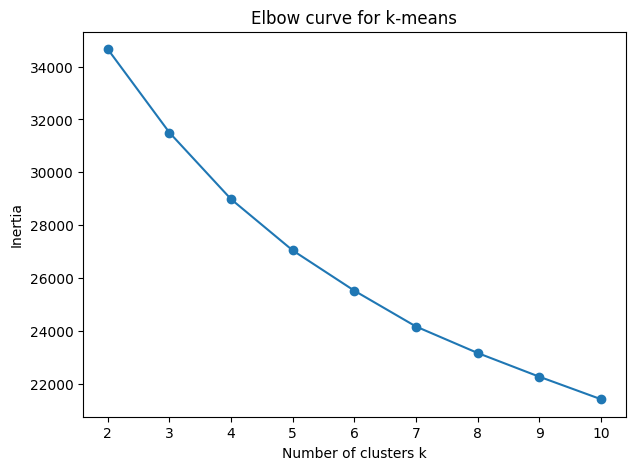

In [12]:
# Part A (a) step 2-3: k-means for k = 2..10; inertia (elbow) and silhouette for each k
ks = range(2, 11)
inertias, sil_scores = {}, {}
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_clu)
    inertias[k] = km.inertia_
    sil_scores[k] = silhouette_score(X_clu, km.labels_, sample_size=3000, random_state=42)
print(pd.DataFrame({'inertia': inertias, 'silhouette': sil_scores}).round(4))

plt.figure(figsize=(7, 5))
plt.plot(list(inertias), list(inertias.values()), 'o-')
plt.title('Elbow curve for k-means')
plt.xlabel('Number of clusters k')
plt.ylabel('Inertia')
plt.savefig(out + 'elbow.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# Choose best_k by silhouette, refit, and show the mean of each feature per cluster
best_k = max(sil_scores, key=sil_scores.get)
print("best_k by silhouette:", best_k, "->", round(sil_scores[best_k], 4))
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X_clu)
df_clu = df_clean[cluster_features].copy()
df_clu['cluster'] = kmeans.labels_
print(df_clu['cluster'].value_counts().sort_index())
print(df_clu.groupby('cluster').mean().round(2))

best_k by silhouette: 2 -> 0.1258
cluster
0    3244
1    3363
Name: count, dtype: int64
         Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  \
cluster                                                            
0                20.30       79.08         6.97            87.68   
1                19.66       80.84         7.09            62.90   

         Tutoring_Sessions  Physical_Activity  
cluster                                        
0                     1.45               2.92  
1                     1.54               3.02  


Explained variance ratio: [0.175  0.1712] | total: 0.3462
     Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  \
PC1          0.515      -0.485        0.160            0.508   
PC2          0.006      -0.420        0.508           -0.415   

     Tutoring_Sessions  Physical_Activity  
PC1             -0.464             -0.015  
PC2              0.147              0.610  


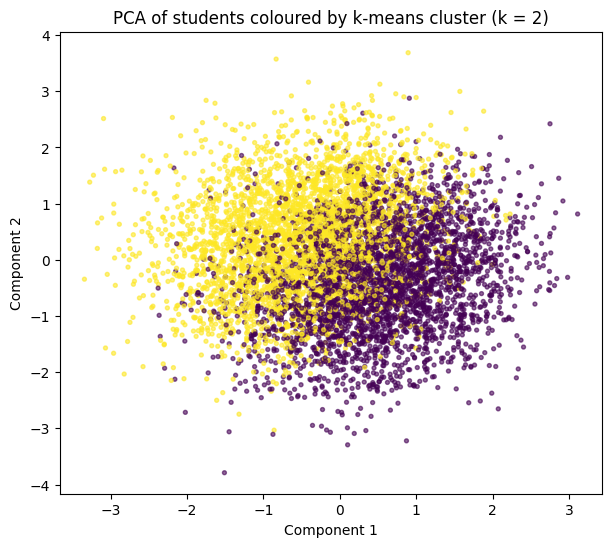

In [14]:
# Part A (b): PCA to two components and the explained variance
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_clu)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4),
      "| total:", round(pca.explained_variance_ratio_.sum(), 4))
print(pd.DataFrame(pca.components_, columns=cluster_features, index=['PC1', 'PC2']).round(3))

plt.figure(figsize=(7, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans.labels_, cmap='viridis', s=8, alpha=0.6)
plt.title(f'PCA of students coloured by k-means cluster (k = {best_k})')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.savefig(out + 'pca_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

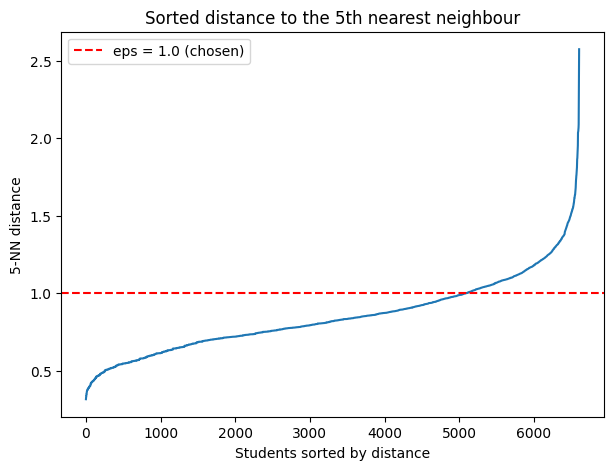

5-NN distance percentiles (50, 90, 95, 99): [0.82  1.165 1.293 1.607]


In [15]:
# Part A (c) step 1: k-distance plot to read eps for DBSCAN (min_samples = 5)
nn = NearestNeighbors(n_neighbors=5).fit(X_clu)
dist, _ = nn.kneighbors(X_clu)
kdist = np.sort(dist[:, -1])
plt.figure(figsize=(7, 5))
plt.plot(kdist)
plt.axhline(1.0, color='red', linestyle='--', label='eps = 1.0 (chosen)')
plt.title('Sorted distance to the 5th nearest neighbour')
plt.xlabel('Students sorted by distance')
plt.ylabel('5-NN distance')
plt.legend()
plt.show()
print("5-NN distance percentiles (50, 90, 95, 99):", np.percentile(kdist, [50, 90, 95, 99]).round(3))

In [16]:
# Part A (c) step 2: DBSCAN with the eps read from the plot (the bend before the steep rise)
dbscan = DBSCAN(eps=1.0, min_samples=5).fit(X_clu)
dbscan_labels = dbscan.labels_
n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int((dbscan_labels == -1).sum())
print("DBSCAN clusters:", n_clusters_db, "| noise points:", n_noise, f"({n_noise / len(dbscan_labels) * 100:.2f}%)")
print("k-means clusters:", best_k, "| noise points: 0 (every student is forced into a cluster)")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN clusters: 3 | noise points: 754 (11.41%)
k-means clusters: 2 | noise points: 0 (every student is forced into a cluster)
-1     754
 0    5846
 1       5
 2       2
Name: count, dtype: int64


In [17]:
# Part B (d): Q-learning on FrozenLake-v1; the seed is the last three digits of COM/0048/23
import gymnasium as gym
SEED = 823
ARROWS = {0: '<', 1: 'v', 2: '>', 3: '^'}   # gymnasium actions: 0 left, 1 down, 2 right, 3 up

def train_q(slippery, episodes=2000, alpha=0.1, gamma=0.99, eps_start=1.0, eps_min=0.01, eps_decay=0.997):
    # Train a Q-table with a decaying epsilon-greedy policy; returns Q, success rates and logged updates
    env = gym.make('FrozenLake-v1', is_slippery=slippery)
    rng = np.random.default_rng(SEED)
    Q = np.zeros((16, 4))
    eps, wins, success_rates, updates = eps_start, [], [], []
    state, _ = env.reset(seed=SEED)
    for ep in range(episodes):
        if ep > 0:
            state, _ = env.reset()
        done = False
        while not done:
            if rng.random() < eps:
                action = int(rng.integers(4))                       # explore: random action
            else:
                best = np.flatnonzero(Q[state] == Q[state].max())   # exploit: best action, ties broken at random
                action = int(rng.choice(best))
            nxt, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            q_before = Q[state, action]
            best_next = 0.0 if terminated else Q[nxt].max()
            Q[state, action] = q_before + alpha * (reward + gamma * best_next - q_before)
            if len(updates) < 100000:
                updates.append((state, action, q_before, reward, best_next, Q[state, action]))
            state = nxt
        wins.append(reward)
        eps = max(eps_min, eps * eps_decay)
        if (ep + 1) % 100 == 0:
            success_rates.append(float(np.mean(wins[-100:])))
    return Q, success_rates, updates

def print_policy(Q):
    # Print the greedy action of every safe state as an arrow on the 4 x 4 grid
    holes, goal = [5, 7, 11, 12], 15
    for r in range(4):
        row = ''
        for c in range(4):
            s = r * 4 + c
            row += ' H ' if s in holes else (' G ' if s == goal else f' {ARROWS[int(np.argmax(Q[s]))]} ')
        print(row)

# Deterministic lake
Q, success_rates, updates = train_q(slippery=False)
print("Success rate per 100 episodes:", [round(x, 2) for x in success_rates])
print("Learned policy (is_slippery=False):")
print_policy(Q)

Success rate per 100 episodes: [0.0, 0.01, 0.22, 0.54, 0.66, 0.79, 0.79, 0.9, 0.9, 0.92, 0.95, 0.97, 0.95, 0.99, 0.97, 0.99, 1.0, 1.0, 0.98, 1.0]
Learned policy (is_slippery=False):
 v  <  <  < 
 v  H  ^  H 
 >  >  v  H 
 H  >  >  G 


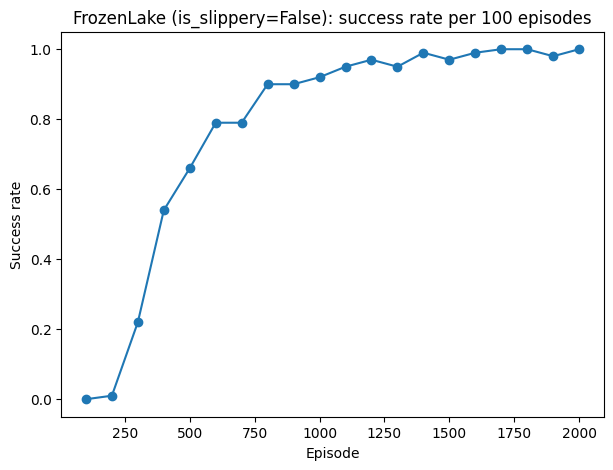

Slippery success rate per 100 episodes: [0.04, 0.02, 0.09, 0.03, 0.11, 0.22, 0.22, 0.3, 0.32, 0.33, 0.42, 0.48, 0.6, 0.69, 0.63, 0.63, 0.71, 0.7, 0.66, 0.71]
Learned policy (is_slippery=True):
 <  ^  <  < 
 <  H  >  H 
 ^  v  <  H 
 H  >  v  G 
Last 500 episodes: not slippery = 0.99, slippery = 0.68


In [18]:
# Plot the success rate per 100 episodes for the deterministic lake
plt.figure(figsize=(7, 5))
plt.plot(range(100, 2001, 100), success_rates, 'o-')
plt.title('FrozenLake (is_slippery=False): success rate per 100 episodes')
plt.xlabel('Episode')
plt.ylabel('Success rate')
plt.ylim(-0.05, 1.05)
plt.savefig(out + 'success_rate.png', dpi=150, bbox_inches='tight')
plt.show()

# Repeat on the slippery lake and compare
Q_slip, success_slip, _ = train_q(slippery=True)
print("Slippery success rate per 100 episodes:", [round(x, 2) for x in success_slip])
print("Learned policy (is_slippery=True):")
print_policy(Q_slip)
print(f"Last 500 episodes: not slippery = {np.mean(success_rates[-5:]):.2f}, slippery = {np.mean(success_slip[-5:]):.2f}")

In [19]:
# Exam skill: show one real Q-learning update from training and check it by hand
# Pick the first update with a reward of 1 (the first time the goal was reached)
s, a, q_before, reward, best_next, q_after = next(u for u in updates if u[3] == 1)
print(f"state={s}, action={a}, Q before={q_before}, reward={reward}, best next Q={best_next}, Q after={q_after:.4f}")
print("Check: Q after = Q before + alpha * (reward + gamma * best next Q - Q before)")
print(f"       = {q_before} + 0.1 * ({reward} + 0.99 * {best_next} - {q_before}) = {q_before + 0.1 * (reward + 0.99 * best_next - q_before):.4f}")

# A second update that uses a non-zero best next Q (information flowing backwards)
s, a, q_before, reward, best_next, q_after = next(u for u in updates if u[4] > 0 and u[3] == 0)
print(f"\nstate={s}, action={a}, Q before={q_before:.4f}, reward={reward}, best next Q={best_next:.4f}, Q after={q_after:.4f}")
print(f"Check: {q_before:.4f} + 0.1 * (0 + 0.99 * {best_next:.4f} - {q_before:.4f}) = {q_before + 0.1 * (0.99 * best_next - q_before):.4f}")

state=14, action=2, Q before=0.0, reward=1, best next Q=0.0, Q after=0.1000
Check: Q after = Q before + alpha * (reward + gamma * best next Q - Q before)
       = 0.0 + 0.1 * (1 + 0.99 * 0.0 - 0.0) = 0.1000

state=13, action=2, Q before=0.0000, reward=0, best next Q=0.1000, Q after=0.0099
Check: 0.0000 + 0.1 * (0 + 0.99 * 0.1000 - 0.0000) = 0.0099


In [20]:
# Self-check: graded variable names and basic properties
assert len(inertias) == 9 and len(sil_scores) == 9 and best_k in sil_scores
assert pca.n_components == 2 and len(dbscan_labels) == len(df_clean)
assert Q.shape == (16, 4) and len(success_rates) == 20
print("Task 7 checks passed")

Task 7 checks passed


### Cluster Names

Although the silhouette score is very low (`0.1258` at $k = 2$, `0.1214` at $k = 3$, `0.1242` at $k = 10$), showing that the students form a continuous cloud rather than distinct natural groups, K-means splits the cohort almost entirely along `Previous_Scores` while leaving other habits nearly identical (e.g., `Hours_Studied` `20.3` vs. `19.7`):
- **Cluster 0 — "Strong Starters" (`3,244` students):** Students entering with strong prior academic foundations (`Previous_Scores` mean `87.68`), even though their day-to-day study hours and attendance closely resemble the rest of the cohort.
- **Cluster 1 — "Needs a Boost" (`3,363` students):** Students with weaker prior academic results (`Previous_Scores` mean `62.90`) who put in comparable daily effort (`19.7` study hours/week) and would benefit most from targeted foundational support.

### Written Answer: Unsupervised Structure, Outlier Handling, and Reinforcement Learning

**1. Meaningful Cluster Names & Structural Honesty:**
- The two K-means segments can be named **"Strong Starters"** (`Previous_Scores` mean `87.68`) and **"Needs a Boost"** (`Previous_Scores` mean `62.90`).
- However, the overall cluster structure is weak: silhouette scores stay near `0.12` across all $k$, and the first two PCA components capture only `34.62%` of total variance (`0.1750` and `0.1712`) because the six numerical features are nearly uncorrelated, leaving no sharp boundaries for two components or centroids to separate cleanly.

**2. Roles of $\alpha$, $\gamma$, and $\epsilon$ in Q-Learning:**
- **Learning Rate ($\alpha = 0.1$):** Controls how aggressively each new experience updates the existing Q-value estimate—moving `10%` of the way toward the new target (for example, updating state `14`, action `2` from `0.0` to `0.0 + 0.1 * (1 + 0.99 * 0 - 0) = 0.1000`, and propagating backward to state `13` as `0.0099`).
- **Discount Factor ($\gamma = 0.99$):** Governs how much weight the agent gives to future rewards versus immediate ones; `0.99` makes the agent far-sighted so it values reaching the distant goal over short-term steps.
- **Exploration Rate ($\epsilon$):** Sets the probability of choosing a random exploratory action rather than the highest-valued greedy action (with random tie-breaking when Q-values are equal so the agent does not get stuck repeatedly choosing `"left"`). Decaying $\epsilon$ over time ensures the agent explores broadly early on and exploits its learned policy later.

**3. Why the Slippery Lake Is Harder:**
- On the deterministic (non-slippery) lake, every action moves reliably in the chosen direction, allowing success per 100 episodes to climb steadily from `0.00` to `1.00` (`0.99` across the last 500 episodes).
- On the **slippery lake**, stochastic transitions mean the agent only moves in the intended direction part of the time and slips perpendicularly otherwise; even an optimal policy occasionally slides into a hole, capping peak success around `0.66–0.71` (`0.68` over the final 500 episodes) and requiring far more episodes to stabilize.

**4. K-Means vs. DBSCAN for Students with Unusual Values:**
- **DBSCAN** is far better suited for handling students with unusual values. While K-means forces every single student into a cluster—allowing extreme profiles to pull cluster centroids—DBSCAN groups dense regions (`5,846`, `5`, and `2` students at `eps = 1.0`, `min_samples = 5`, chosen where the 5th-neighbor distance curve turns sharply upward beyond its `0.82` median toward the `1.165` 90th percentile) and explicitly flags `754` atypical students (`11.41%`) as **noise (`-1`)**.